# Scenario Simulation & Recommendations
Simulate factory reassignment, estimate profit impact, score and rank top-N, compute KPIs.


In [1]:
# Cell 1: setup
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import *
from src.modeling import load_model
from src.simulate import *


In [2]:
# Cell 2: load data and model
df = pd.read_csv(CLEAN_FILE)
model = load_model()
print(df.shape, "|", type(model.named_steps["model"]).__name__)
print(df["product"].nunique(), "products")

(4090, 35) | RandomForestRegressor
15 products


In [3]:
# Cell 3: is the assumed freight rate realistic? (tune COST_PER_UNIT_KM in config.py)
freight = df["distance_km"] * df["units"] * COST_PER_UNIT_KM
print("Avg freight per order ($):     ", round(freight.mean(), 2))
print("Avg gross profit per order ($):", round(df["gross_profit"].mean(), 2))
print("Freight as % of gross profit:  ", round(freight.sum() / df["gross_profit"].sum() * 100, 1))

Avg freight per order ($):      3.76
Avg gross profit per order ($): 9.12
Freight as % of gross profit:   41.3


In [4]:
# Cell 4: simulate one product and look at the raw table
test_product = df["product"].iloc[0]
one = simulate_product(df, model, test_product)
print(test_product)
one[["candidate_factory", "is_current", "avg_distance_km", "lead_new", "lead_delta_days",
     "lead_reduction_pct", "profit_change_pct", "risk_reduction_pp", "confidence"]].round(2)

Wonka Bar - Milk Chocolate


,candidate_factory,is_current,avg_distance_km,lead_new,lead_delta_days,lead_reduction_pct,profit_change_pct,risk_reduction_pp,confidence
0,Lot's O' Nuts,False,2182.41,1349.39,1.95,-0.14,-5.81,10.23,36.71
1,Wicked Choccy's,True,1840.23,1347.44,0.00,0.00,-0.00,0.00,NaN
2,Sugar Shack,False,1809.92,1350.33,2.89,-0.21,1.23,20.22,38.13
3,Secret Factory,False,1485.85,1346.03,-1.42,0.11,8.67,20.22,35.71
4,The Other Factory,False,1553.72,1346.28,-1.17,0.09,7.27,20.22,34.50


In [5]:
# Cell 5: simulate all products and save
scen = simulate_all(df, model)
scen.to_csv(SCENARIOS_FILE, index=False)
bounds = make_bounds(scen)
print(scen.shape, "|", scen["product"].nunique(), "products x", scen["candidate_factory"].nunique(), "factories")
print(bounds)

(75, 21) | 15 products x 5 factories
{'lead_reduction_pct': (-2.3920692547727396, 2.907203733633822), 'profit_change_pct': (-209.06660645354788, 71.29369602131081), 'risk_reduction_pp': (-100.0, 20.216606498194945)}


In [6]:
# Cell 6: does the priority slider change the ranking? (Top pick per product at 3 settings)
rows = []
for p in sorted(df["product"].unique()):
    row = {"product": p}
    for pr in (0.0, 0.5, 1.0):
        r = recommend(df, model, bounds, p, priority=pr, top_n=1)
        row[f"top @ priority {pr}"] = r["candidate_factory"].iloc[0] if len(r) else "(keep current)"
    rows.append(row)
pd.DataFrame(rows)

,product,top @ priority 0.0,top @ priority 0.5,top @ priority 1.0
0,Everlasting Gobstopper,(keep current),(keep current),(keep current)
1,Fizzy Lifting Drinks,Wicked Choccy's,Wicked Choccy's,Wicked Choccy's
2,Fun Dip,Secret Factory,Secret Factory,The Other Factory
3,Hair Toffee,Lot's O' Nuts,Lot's O' Nuts,Lot's O' Nuts
4,Kazookles,Secret Factory,Secret Factory,Secret Factory
5,Laffy Taffy,(keep current),(keep current),(keep current)
6,Lickable Wallpaper,(keep current),(keep current),(keep current)
7,Nerds,Wicked Choccy's,Wicked Choccy's,Lot's O' Nuts
8,SweeTARTS,Secret Factory,Secret Factory,Secret Factory
9,Wonka Bar - Fudge Mallows,Wicked Choccy's,Wicked Choccy's,Wicked Choccy's


In [7]:
# Cell 7: KPIs
kpis = compute_kpis(df, model, bounds, priority=0.5)
for k, v in kpis.items():
    print(f"{k:32s} {v:8.2f}")

lead_time_reduction_pct              0.97
profit_impact_stability_pct         90.00
scenario_confidence                 20.87
recommendation_coverage_pct         66.67


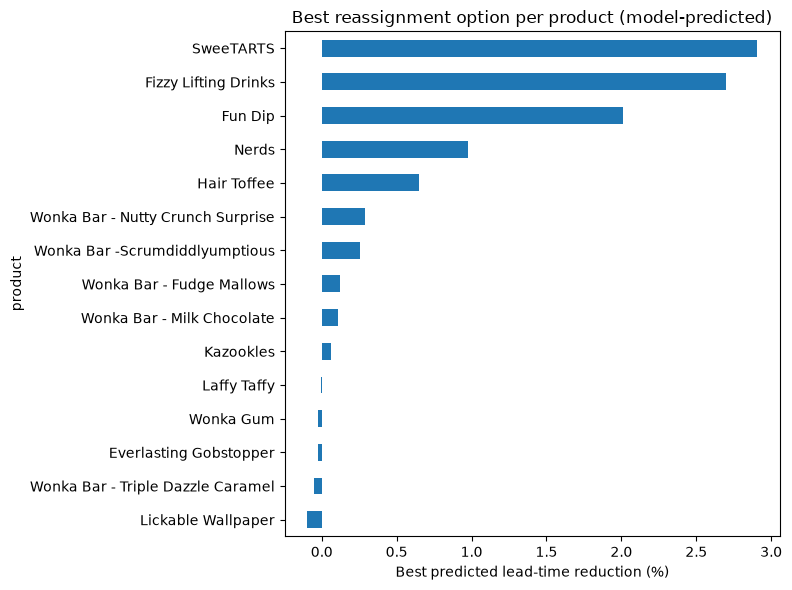

In [8]:
# Cell 8: best option per product (chart for the paper)
best = (scen[~scen["is_current"]].sort_values("lead_reduction_pct", ascending=False)
        .groupby("product").head(1).sort_values("lead_reduction_pct"))
ax = best.plot.barh(x="product", y="lead_reduction_pct", legend=False, figsize=(8, 6))
ax.set_xlabel("Best predicted lead-time reduction (%)")
ax.set_title("Best reassignment option per product (model-predicted)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_reduction_per_product.png", dpi=150)
plt.show()

In [9]:
# Cell 9: verification
s = pd.read_csv(SCENARIOS_FILE)
n_fac = len(load_factories())
assert (s.groupby("product").size() == n_fac).all(), "Each product needs one row per factory"
cur = s[s["is_current"]]
assert (cur["lead_delta_days"].abs() < 1e-9).all(), "Current factory must show zero change"
assert (cur["profit_change_pct"].abs() < 1e-9).all(), "Current factory must show zero profit change"
assert s[["lead_new", "avg_distance_km", "profit_change_pct", "risk_reduction_pp"]].notna().all().all()
sc = score(s, bounds, 0.5)["score"]
assert sc.between(0, 100).all(), "Scores must be in 0-100"
conf = s.loc[~s["is_current"], "confidence"]
assert conf.between(0, 100).all(), "Confidence must be in 0-100"
print("STEP 5 CHECKS PASSED | products:", s["product"].nunique(),
      "| mean confidence:", round(conf.mean(), 1),
      "| coverage %:", round(kpis["recommendation_coverage_pct"], 1))

STEP 5 CHECKS PASSED | products: 15 | mean confidence: 18.7 | coverage %: 66.7
